# Предсказание цены домов (Ames Housing)
 
Регрессия: по 79 признакам дома нужно предсказать цену продажи `SalePrice`. Работа включает предобработку данных, исследовательский анализ, подбор гиперпараметров с помощью Optuna и построение ансамбля моделей (`StackingRegressor`).
 
## Оглавление
 
- [1. Введение](#1.-Введение)
- [2. Подготовка окружения](#2.-Подготовка-окружения)
    - [2.1 Отслеживание прогресса поиска](#2.1-Отслеживание-прогресса-поиска)
    - [2.2 Удаление выбросов при обучении](#2.2-Удаление-выбросов-при-обучении)
    - [2.3 Список используемых библиотек](#2.3-Список-используемых-библиотек)
- [3. Загрузка данных и первичный анализ](#3.-Загрузка-данных-и-первичный-анализ)
- [4. Предобработка данных](#4.-Предобработка-данных)
    - [4.1 Типы признаков](#4.1-Типы-признаков)
    - [4.2 Пропуски в MasVnrArea](#4.2-Пропуски-в-MasVnrArea)
    - [4.3 Пропуски в LotFrontage](#4.3-Пропуски-в-LotFrontage)
    - [4.4 Удаление признака Alley](#4.4-Удаление-признака-Alley)
    - [4.5 Признаки, связанные с годами](#4.5-Признаки,-связанные-с-годами)
    - [4.6 Признаки отсутствия объекта](#4.6-Признаки-отсутствия-объекта)
    - [4.7 Оставшиеся пропуски](#4.7-Оставшиеся-пропуски)
    - [4.8 Вывод по предобработке](#4.8-Вывод-по-предобработке)
- [5. Исследовательский анализ данных](#5.-Исследовательский-анализ-данных)
- [6. Обучение моделей](#6.-Обучение-моделей)
    - [6.1 Подготовка данных для обучения](#6.1-Подготовка-данных-для-обучения)
    - [6.2 Базовый стек](#6.2-Базовый-стек)
    - [6.3 Расширение ансамбля](#6.3-Расширение-ансамбля)
    - [6.4 Итоговый стек](#6.4-Итоговый-стек)
- [7. Итоговый вывод](#7.-Итоговый-вывод)


## 1. Введение
 
**Задача.** Предсказать цену продажи дома (`SalePrice`) по 79 признакам: площади, качество отделки, год постройки, район и другие характеристики.
 
**Данные.** Обучающая выборка: 1460 записей и 81 столбец (включая `Id` и целевую переменную). Тестовая выборка содержит те же признаки, но без цены.
 
**Метрика.** RMSE, рассчитанный на логарифме цены. Такая метрика оценивает относительную ошибку: промах в 20 000 $ существеннее $ для дома за 100 000 , чем для дома за 500 000 $.
 
**Основные этапы:**
 
1. Первичный анализ и предобработка данных.
2. Исследовательский анализ и выбор способов преобразования признаков.
3. Подбор гиперпараметров моделей с помощью Optuna.
4. Объединение моделей в ансамбль (`StackingRegressor`) и сравнение с отдельными моделями.


## 2. Подготовка окружения
 
Работа выполнена на Python 3.11.7. Список зависимостей сохраняется в файл `requirements.txt` (см. раздел 2.3), установить их можно командой `pip install -r requirements.txt`.


In [1]:
#%pip install -q -r requirements.txt

In [2]:
import os
import math
import optuna
import time
import json
import random
import gc
import warnings
import keras
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt

from optuna.visualization import (plot_optimization_history, plot_param_importances,
                                  plot_slice, plot_parallel_coordinate)

from data_profiling import ProfileReport

from tqdm.auto import tqdm

from keras import layers, regularizers

from lightgbm import LGBMRegressor

from sklearn.exceptions import ConvergenceWarning
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.svm import SVR
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, FunctionTransformer
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.model_selection import RepeatedKFold, KFold, cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error

from catboost import CatBoostRegressor

RANDOM_STATE = 230325
VAL_SIZE = 0.1
pd.set_option('display.max_rows', None)      # показывать все строки
pd.set_option('display.max_columns', None)   # показывать все столбцы
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

### 2.1 Отслеживание прогресса поиска
 
Класс `TqdmCallback` выводит прогресс подбора гиперпараметров: число завершённых и отсечённых триалов, лучший результат и оставшееся время.


In [3]:
class TqdmCallback:
    def __init__(self, desc, n_trials=None, timeout_s=None):
        self.n_trials, self.timeout_s = n_trials, timeout_s
        self.t0 = time.time()
        self.pbar = tqdm(total=n_trials, desc=desc, unit="trial")

    def __call__(self, study, trial):
        states = [t.state.name for t in study.trials]
        n_done, n_pruned = states.count("COMPLETE"), states.count("PRUNED")
        info = {
            "done": n_done,
            "pruned": n_pruned,
            "last": f"{trial.value:.4f}" if trial.value is not None else "pruned",
        }
        if n_done:
            info["best"] = f"{study.best_value:.4f}"
        if self.timeout_s:
            left = max(0, self.timeout_s - (time.time() - self.t0))
            info["left"] = f"{int(left // 3600)}h{int(left % 3600 // 60):02d}m"
        self.pbar.set_postfix(info)
        self.pbar.update(1)

    def close(self):
        self.pbar.close()

### 2.2 Удаление выбросов при обучении
 
Класс `TrimmedRegressor` перед обучением модели удаляет строки, в которых значение хотя бы одного количественного признака превышает верхнюю границу `Q3 + k·IQR`. Особенности:
 
- границы считаются только по ненулевым значениям: нули в этих признаках означают отсутствие объекта (нет подвала, террасы и т. п.), и такие записи не удаляются;
- удаление выполняется только при обучении (`fit`) и только в обучающей части фолда, поэтому на оценку качества оно не влияет;
- коэффициент `k` подбирается Optuna вместе с остальными гиперпараметрами.


In [4]:
class TrimmedRegressor(RegressorMixin, BaseEstimator):
    
    def __init__(self, estimator, trim_cols, k=1.5, min_nonzero=20):
        self.estimator = estimator
        self.trim_cols = trim_cols
        self.k = k
        self.min_nonzero = min_nonzero

    def fit(self, X, y):
        keep = np.ones(len(X), dtype=bool)
        self.fences_ = {}
        for c in self.trim_cols:
            v = X[c]
            nz = v[v != 0]
            if len(nz) < self.min_nonzero:      # слишком мало данных для границы
                continue
            q1, q3 = nz.quantile([0.25, 0.75])
            fence = q3 + self.k * (q3 - q1)
            self.fences_[c] = fence
            keep &= (v <= fence).to_numpy()
        self.n_removed_ = int((~keep).sum())
        self.estimator_ = clone(self.estimator).fit(X[keep], np.asarray(y)[keep])
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

### 2.3 Список используемых библиотек
 
Используемые библиотеки сохраняются в `requirements.txt` с помощью `pipreqs`.

In [5]:
#!pipreqs . --scan-notebooks --force --mode no-pin

## 3. Загрузка данных и первичный анализ
 
Загружаем обучающую и тестовую выборки и просматриваем их структуру.

In [6]:
def load_csv(path):
    if os.path.exists(path):
        df = pd.read_csv(path)
    else:
        print('Something is wrong')
        
    display(df.head(10))  
    print('Размер датафрейма:')
    display(df.shape)
    print('Тип данных:')
    display(df.dtypes)
    print('Количество пропусков:')
    display(df.isna().sum()[lambda s: s > 0])
    print('Количество полных дубликатов:', df.duplicated().sum())
    return df

In [7]:
df_train = load_csv('./datasets/train.csv')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,1.5Fin,5,5,1993,1995,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,Wood,Gd,TA,No,GLQ,732,Unf,0,64,796,GasA,Ex,Y,SBrkr,796,566,0,1362,1,0,1,1,1,1,TA,5,Typ,0,NaN,Attchd,1993.0,Unf,2,480,TA,TA,Y,40,30,0,320,0,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,1Story,8,5,2004,2005,Gable,CompShg,VinylSd,VinylSd,Stone,186.0,Gd,TA,PConc,Ex,TA,Av,GLQ,1369,Unf,0,317,1686,GasA,Ex,Y,SBrkr,1694,0,0,1694,1,0,2,0,3,1,Gd,7,Typ,1,Gd,Attchd,2004.0,RFn,2,636,TA,TA,Y,255,57,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NWAmes,PosN,Norm,1Fam,2Story,7,6,1973,1973,Gable,CompShg,HdBoard,HdBoard,Stone,240.0,TA,TA,CBlock,Gd,TA,Mn,ALQ,859,BLQ,32,216,1107,GasA,Ex,Y,SBrkr,1107,983,0,2090,1,0,2,1,3,1,TA,7,Typ,2,TA,Attchd,1973.0,RFn,2,484,TA,TA,Y,235,204,228,0,0,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,1.5Fin,7,5,1931,1950,Gable,CompShg,BrkFace,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,Unf,0,952,952,GasA,Gd,Y,FuseF,1022,752,0,1774,0,0,2,0,2,2,TA,8,Min1,2,TA,Detchd,1931.0,Unf,2,468,Fa,TA,Y,90,0,205,0,0,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,BrkSide,Artery,Artery,2fmCon,1.5Unf,5,6,1939,1950,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,BrkTil,TA,TA,No,GLQ,851,Unf,0,140,991,GasA,Ex,

Размер датафрейма:


(1460, 81)

Тип данных:


Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1         int64
BsmtFinType2      object
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
Heating           object


Количество пропусков:


LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

Количество полных дубликатов: 0


In [8]:
df_test = load_csv('./datasets/test.csv')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,6,1998,1998,Gable,CompShg,VinylSd,VinylSd,BrkFace,20.0,TA,TA,PConc,TA,TA,No,GLQ,602.0,Unf,0.0,324.0,926.0,GasA,Ex,Y,SBrkr,926,678,0,1604,0.0,0.0,2,1,3,1,Gd,7,Typ,1,Gd,Attchd,1998.0,Fin,2.0,470.0,TA,TA,Y,360,36,0,0,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,Gtl,StoneBr,Norm,Norm,TwnhsE,1Story,8,5,1992,1992,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,263.0,Unf,0.0,1017.0,1280.0,GasA,Ex,Y,SBrkr,1280,0,0,1280,0.0,0.0,2,0,2,1,Gd,5,Typ,0,NaN,Attchd,1992.0,RFn,2.0,506.0,TA,TA,Y,0,82,0,0,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal
5,1466,60,RL,75.0,10000,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1993,1994,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,763.0,763.0,GasA,Gd,Y,SBrkr,763,892,0,1655,0.0,0.0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1993.0,Fin,2.0,440.0,TA,TA,Y,157,84,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
6,1467,20,RL,NaN,7980,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,1Story,6,7,1992,2007,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,TA,Gd,PConc,Gd,TA,No,ALQ,935.0,Unf,0.0,233.0,1168.0,GasA,Ex,Y,SBrkr,1187,0,0,1187,1.0,0.0,2,0,3,1,TA,6,Typ,0,NaN,Attchd,1992.0,Fin,2.0,420.0,TA,TA,Y,483,21,0,0,0,0,NaN,GdPrv,Shed,500,3,2010,WD,Normal
7,1468,60,RL,63.0,8402,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1998,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,789.0,789.0,GasA,Gd,Y,SBrkr,789,676,0,1465,0.0,0.0,2,1,3,1,TA,7,Typ,1,Gd,Attchd,1998.0,Fin,2.0,393.0,TA,TA,Y,0,75,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
8,1469,20,RL,85.0,10176,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,1Story,7,5,1990,1990,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,TA,TA,PConc,Gd,TA,Gd,GLQ,637.0,Unf,0.0,663.0,1300.0,GasA,Gd,Y,SBrkr,1341,0,0,1341,1.0,0.0,1,1,2,1,Gd,5,Typ,1,Po,Attchd,1990.0,Unf,2.0,506.0,TA,TA,Y,192,0,0,0,0,0,NaN,NaN,NaN,0,2,2010,WD,Normal
9,1470,20,RL,70.0,8400,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,4,5,1970,1970,Gable,CompShg,Plywood

Размер датафрейма:


(1459, 80)

Тип данных:


Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1       float64
BsmtFinType2      object
BsmtFinSF2       float64
BsmtUnfSF        float64
TotalBsmtSF      float64
Heating           object


Количество пропусков:


MSZoning           4
LotFrontage      227
Alley           1352
Utilities          2
Exterior1st        1
Exterior2nd        1
MasVnrType       894
MasVnrArea        15
BsmtQual          44
BsmtCond          45
BsmtExposure      44
BsmtFinType1      42
BsmtFinSF1         1
BsmtFinType2      42
BsmtFinSF2         1
BsmtUnfSF          1
TotalBsmtSF        1
BsmtFullBath       2
BsmtHalfBath       2
KitchenQual        1
Functional         2
FireplaceQu      730
GarageType        76
GarageYrBlt       78
GarageFinish      78
GarageCars         1
GarageArea         1
GarageQual        78
GarageCond        78
PoolQC          1456
Fence           1169
MiscFeature     1408
SaleType           1
dtype: int64

Количество полных дубликатов: 0


### 3.1 Вывод по первичному анализу
 
- **Пропуски.** Есть как в категориальных, так и в числовых признаках. Способ заполнения выбирается отдельно для каждого столбца: нулём, значением `"None"` (объекта нет), модой или удалением столбца.
- **Размерность.** Признаков много (81) при небольшом числе записей (1460), что повышает риск переобучения. Для линейных моделей и нейросетей число признаков стоит сократить, для деревьев это менее критично.
- **Типы данных.** Часть столбцов имеет тип `int64`, но по смыслу является категориями (например, `MSSubClass`). Их нужно привести к категориальному типу.
- **Новые признаки.** Можно создать признаки «время с момента постройки или реконструкции» и бинарные флаги отсутствия объекта (подвал, гараж и т. п.).
- **Дубликаты.** Полных дубликатов нет. Неявные дубликаты (разное написание одной категории) требуют отдельной проверки. (В данной работе найдены не были)

## 4. Предобработка данных
 
Все преобразования выполняются вручную и одинаково применяются к обучающей и тестовой выборкам. Значения для заполнения (моды) берутся только из обучающей выборки, чтобы не допустить утечки данных.

In [9]:
test_id = df_test['Id']
df_train, df_test = df_train.drop('Id', axis = 1), df_test.drop('Id', axis = 1)

### 4.1 Типы признаков
 
Следующие признаки приводятся к категориальному типу, так как по описанию данных они не являются количественными:
 
- `MSSubClass` — код типа жилья, участвующего в сделке;
- `YrSold` — год продажи;
- `MoSold` — месяц продажи.

In [10]:
cols = ['MSSubClass', 'YrSold', 'MoSold']
df_train[cols] = df_train[cols].astype("str")
df_test[cols] = df_test[cols].astype("str")

### 4.2 Пропуски в MasVnrArea
 
В `MasVnrArea` (площадь каменной облицовки) значение `None` означает отсутствие облицовки, поэтому оно заменяется нулём.

In [11]:
df_train['MasVnrArea'] = df_train['MasVnrArea'].replace('None', 0)
df_test['MasVnrArea'] = df_test['MasVnrArea'].replace('None', 0)

### 4.3 Пропуски в LotFrontage
 
В `LotFrontage` (протяжённость участка вдоль улицы) пропуски заполняются нулём. Исходное предположение: пропуск означает отсутствие выхода участка на улицу. В описании данных это явно не указано, поэтому предположение требует проверки (см. раздел 7).

In [12]:
df_train['LotFrontage'] = df_train['LotFrontage'].fillna(0)
df_test['LotFrontage'] = df_train['LotFrontage'].fillna(0)

### 4.4 Удаление признака Alley
 
В `Alley` (тип доступа со стороны переулка) пропуск означает отсутствие переулка, и такое значение у 1369 из 1460 домов (93.8%). Признак почти константный. Кроме того, он схож по смыслу с `Street` (тип дорожного доступа к участку): у обоих признаков одинаковые значения `Pave` и `Grvl`. Поэтому `Alley` удалён.

In [13]:
df_train = df_train.drop('Alley', axis = 1)
df_test = df_test.drop('Alley', axis = 1)

### 4.5 Признаки, связанные с годами
 
Годы постройки и реконструкции модели интерпретируют хуже, чем длительности. Поэтому `YearBuilt`, `YearRemodAdd` и `GarageYrBlt` заменены на:
 
- `ConstructionAge` — возраст дома на момент выгрузки данных;
- `Years_to_remond` — время между постройкой и реконструкцией в годах (0, если реконструкции не было);
- `GarageAge` — возраст гаража;
- `WasRemod` — бинарный признак: проводилась ли реконструкция.
 
За текущий год принят 2010 — максимальный год в данных; вероятно, выгрузка сделана в этом году. Для домов без гаража `GarageYrBlt` заполнен значением 2010, поэтому у них `GarageAge = 0`; такие дома отличает флаг `NoGarage` (см. раздел 4.6).

In [14]:
df_train[['YearBuilt', 'YearRemodAdd', 'GarageYrBlt']].head(10)

,YearBuilt,YearRemodAdd,GarageYrBlt
0,2003,2003,2003.0
1,1976,1976,1976.0
2,2001,2002,2001.0
3,1915,1970,1998.0
4,2000,2000,2000.0
5,1993,1995,1993.0
6,2004,2005,2004.0
7,1973,1973,1973.0
8,1931,1950,1931.0
9,1939,1950,1939.0


In [15]:
df_train['GarageYrBlt'] = df_train['GarageYrBlt'].fillna(2010).astype('int64') # Привел к целочисленному типу и заполнил пропуски
df_test['GarageYrBlt'] = df_test['GarageYrBlt'].fillna(2010).astype('int64')

df_train['ConstructionAge'] = 2010 - df_train['YearBuilt']
df_train['Years_to_remond'] = abs((2010 - df_train['YearRemodAdd']) - df_train['ConstructionAge'])
df_train['GarageAge'] = 2010 - df_train['GarageYrBlt']
df_train['WasRemod'] = df_train['Years_to_remond'].map(lambda x: 1 if x > 0 else 0)
df_train = df_train.drop(['YearBuilt', 'YearRemodAdd', 'GarageYrBlt'], axis = 1)

df_test['ConstructionAge'] = 2010 - df_test['YearBuilt']
df_test['Years_to_remond'] = abs((2010 - df_test['YearRemodAdd']) - df_test['ConstructionAge'])
df_test['GarageAge'] = 2010 - df_test['GarageYrBlt']
df_test['WasRemod'] = df_test['Years_to_remond'].map(lambda x: 1 if x > 0 else 0)
df_test = df_test.drop(['YearBuilt', 'YearRemodAdd', 'GarageYrBlt'], axis = 1)

df_train[['GarageAge', 'Years_to_remond', 'ConstructionAge', 'WasRemod']].head(5)

,GarageAge,Years_to_remond,ConstructionAge,WasRemod
0,7,0,7,0
1,34,0,34,0
2,9,1,9,1
3,12,55,95,1
4,10,0,10,0


### 4.6 Признаки отсутствия объекта
 
Пропуски в категориальных признаках, связанных с:
 
- подвалом (`BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2`);
- каменной облицовкой (`MasVnrType`);
- гаражом (`GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`);
- камином (`FireplaceQu`);
- бассейном (`PoolQC`);
- ограждением (`Fence`);
- прочими особенностями (`MiscFeature`),
 
означают, что у участка этого объекта нет. Это важная информация, поэтому пропуски заполнены значением `"None"` как отдельной категорией. Дополнительно созданы бинарные флаги `NoBsmt`, `NoMasVnr`, `NoGarage`, `NoFireplace`, `NoPool`, `NoFence`, `NoMisc`.

In [16]:
cols1 = ['NoBsmt', 'NoMasVnr', 'NoGarage', 'NoFireplace', 'NoPool', 'NoFence', 'NoMisc']
cols2 = ['BsmtQual', 'MasVnrType', 'GarageType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']

df_train[cols1] = df_train[cols2].isna()
df_test[cols1] = df_test[cols2].isna()

cols = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType',\
        'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
df_train[cols] = df_train[cols].fillna('None')
df_test[cols] = df_test[cols].fillna('None')

display(df_train.isna().sum()[lambda s: s > 0])
df_test.isna().sum()[lambda s: s > 0] # Проверяем, остались ли пропуски

MasVnrArea    8
Electrical    1
dtype: int64

MSZoning         4
Utilities        2
Exterior1st      1
Exterior2nd      1
MasVnrArea      15
BsmtFinSF1       1
BsmtFinSF2       1
BsmtUnfSF        1
TotalBsmtSF      1
BsmtFullBath     2
BsmtHalfBath     2
KitchenQual      1
Functional       2
GarageCars       1
GarageArea       1
SaleType         1
dtype: int64

### 4.7 Оставшиеся пропуски
 
Оставшиеся пропуски (в обучающей выборке — один в `Electrical`, в тестовой — единичные в нескольких признаках) заполняются модой, вычисленной по обучающей выборке.

In [17]:
modes = df_train.mode().iloc[0]
df_test = df_test.fillna(modes)
df_train = df_train.fillna(modes)

### 4.8 Вывод по предобработке
 
- Пропуски устранены: в признаках «объекта нет» они заменены на `"None"` или нуль, остальные заполнены модой обучающей выборки.
- Годы постройки, реконструкции и постройки гаража заменены на длительности и флаг реконструкции (4 новых признака).
- Добавлено 7 бинарных флагов отсутствия объекта (`NoBsmt`, `NoGarage` и др.).
- Удалён признак `Alley`: он почти константный и дублирует по смыслу `Street`.

## 5. Исследовательский анализ данных
 
Цель этого этапа — найти аномалии, оценить распределения признаков и выбрать способы их преобразования перед обучением.

### 5.1 Визуальный анализ признаков
 
Автоматический отчёт `ydata-profiling` по обучающей выборке: распределения, пропуски, корреляции и предупреждения о дисбалансе.

In [18]:
profile = ProfileReport(df_train, title="Ames Housing") 

In [ ]:
profile.to_notebook_iframe() # Отчет сохранен в файл report.html так как иначе тетрадь не будет отображатсья на github

### 5.2 Вывод по исследовательскому анализу
 
**1. Скошенные количественные признаки.** Большинство количественных признаков (`LotFrontage`, `LotArea`, `TotalBsmtSF` и др.) имеют выраженную правую скошенность и много нулей. Нули означают отсутствие объекта, поэтому такие значения не удаляются и не заполняются. Для уменьшения скошенности применяется логарифмирование `log1p` (ноль остаётся нулём). Для сравнения модели можно также обучить на признаках без логарифмирования.
 
Пример: `LotFrontage` до логарифмирования (нули на графике получены заполнением пропусков, см. раздел 4.3):
 
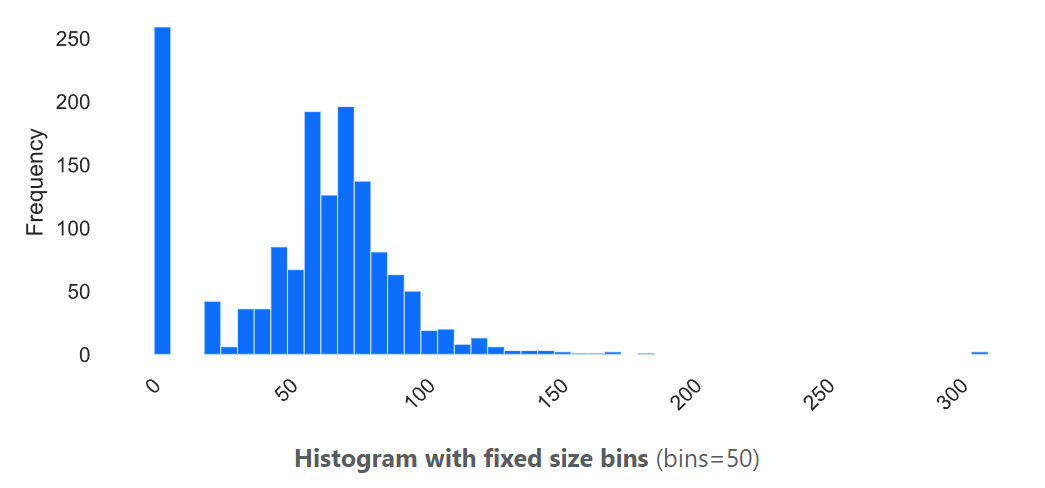
 
После логарифмирования:
 
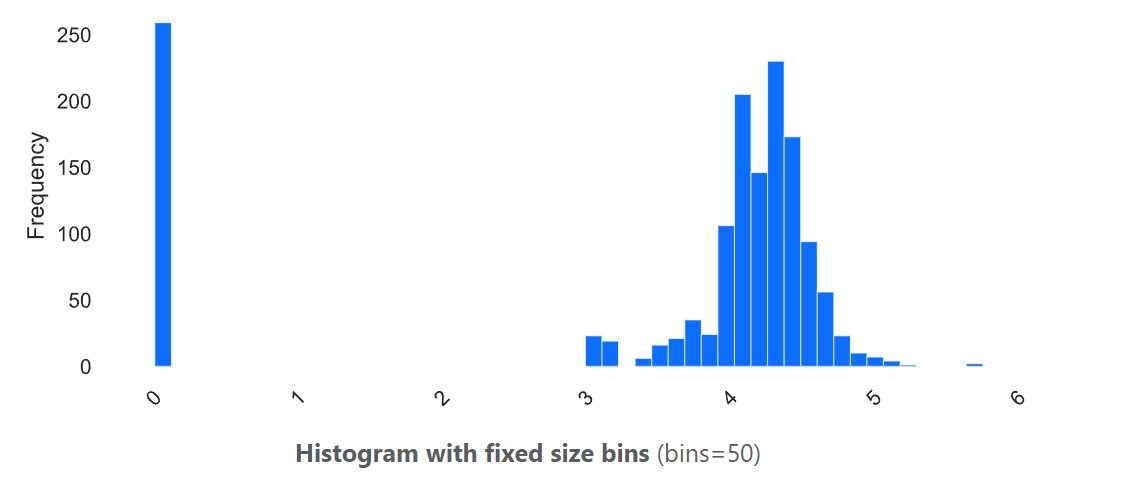
 
**2. Дисбаланс категорий.** Во многих категориальных признаках (`PoolQC`, `MiscFeature`, `Heating` и др.) одна категория занимает почти все записи. Например, в `Heating` значение `GasA` имеет 1428 из 1460 домов:
 
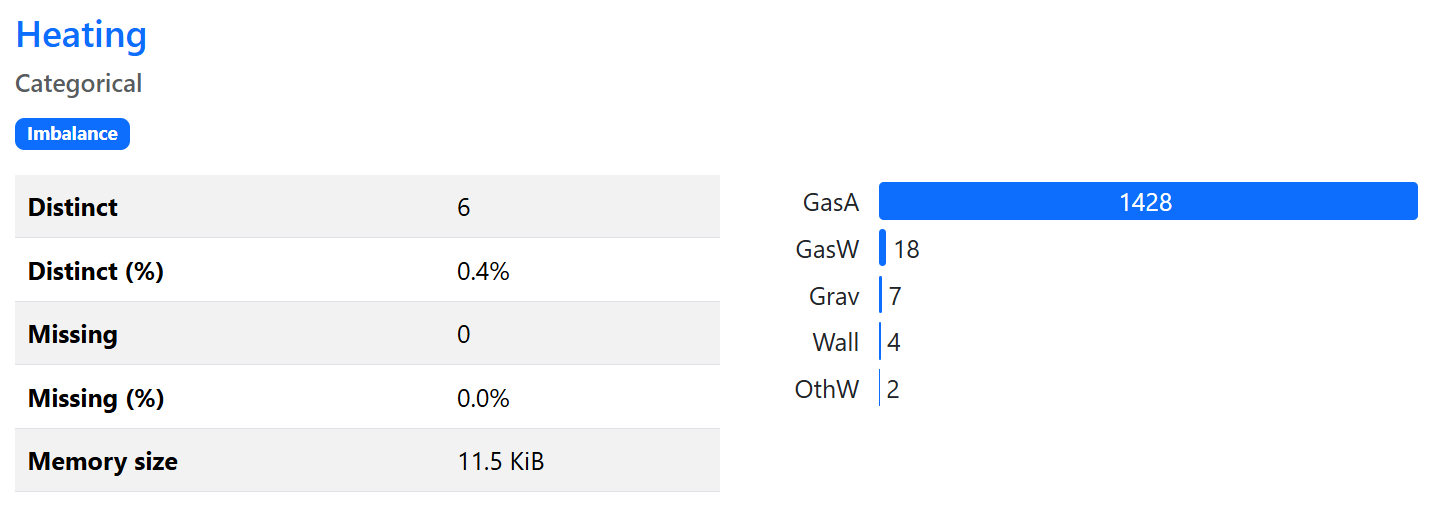
 
Для случайного леса, CatBoost и LightGBM это не критично. Для линейных моделей, SVR и нейросетей создаётся отдельный набор данных: редкие категории объединяются в одну (`Other`), а признаки с почти одинаковым значением у всех записей удаляются (например, `Utilities`: значение отличается только у одной записи).
 
**Что из этого следует:**
 
- к скошенным признакам применяется `log1p` (для деревьев не требуется);
- для линейных моделей, SVR и нейросетей готовится отдельный набор данных с меньшим числом признаков.


## 6. Обучение моделей
 
План: сначала строится базовый стек из трёх моделей с разным принципом работы, затем ансамбль расширяется (ElasticNet, SVR, LightGBM, нейросети) и оценивается итоговый вариант.
 
Во всех экспериментах модели обучаются на `log1p(SalePrice)`, поэтому обычный RMSE соответствует нужной метрике (RMSE на логарифме цены), а предсказание переводится обратно в доллары через `np.expm1`.

### 6.1 Подготовка данных для обучения

Сначала строится базовый ансамбль из Ridge, RandomForest и CatBoost (`StackingRegressor`). Идея стекинга: объединить модели с разным принципом работы, так как каждая находит свои закономерности, и получить более точный и устойчивый прогноз, чем у отдельных алгоритмов.
 
`StackingRegressor` подаёт всем базовым моделям один и тот же `X`, а подготовка признаков у моделей разная:
 
| Модель | Подготовка признаков |
|---|---|
| Ridge | `log1p` для `log_cols`, `StandardScaler` для всех чисел, one-hot для категорий |
| RandomForest | one-hot для категорий, числа без изменений (логарифм и масштабирование не нужны) |
| CatBoost | категории как строки (без one-hot), числа без изменений |
 
Поэтому каждая модель оборачивается в собственный `Pipeline`. Все обучаемые преобразования (масштабирование, кодирование) выполняются внутри пайплайна и обучаются только на обучающей части фолда, что исключает утечку данных.
 
Признаки разделены на три списка: `cat_cols` — категориальные, `num_cols` — количественные и порядковые признаки без преобразования, `log_cols` — скошенные количественные признаки, к которым применяется логарифмирование.

In [20]:
target = 'SalePrice'

cat_cols = ['MSSubClass', 'MSZoning', 'Street', 'LotShape', 'LandContour',
            'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1',
            'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
            'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 
            'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 
            'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 
            'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish',
            'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
            'MoSold', 'YrSold', 'SaleType', 'SaleCondition', 'WasRemod', 
            'NoBsmt', 'NoMasVnr', 'NoGarage', 'NoFireplace', 'NoPool', 'NoFence', 'NoMisc']

num_cols = ['OverallQual', 'OverallCond', 'BedroomAbvGr', 
            'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'KitchenAbvGr',
            'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'ConstructionAge',
            'Years_to_remond', 'GarageAge']

log_cols = ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1',
            'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF',
            '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea',
            'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch',
            'ScreenPorch', 'PoolArea', 'MiscVal']

features = cat_cols + num_cols + log_cols

X = df_train[features].copy()
y = np.log1p(df_train[target])
X_test = df_test[features].copy()

# Категории строго строками
for d in (X, X_test):
    d[cat_cols] = d[cat_cols].astype(str)

### 6.2 Базовый стек
 
Гиперпараметры подбираются с помощью **Optuna**. Один *триал* — это один набор параметров, который оценивается кросс-валидацией на одинаковых для всех моделей фолдах; значение целевой функции — средний RMSE на логарифме цены.
 
- Сэмплер **TPE** сначала пробует случайные наборы, затем концентрируется на областях с лучшими результатами.
- **MedianPruner** досрочно останавливает триал, если после нескольких фолдов он хуже медианы остальных.
- Результаты записываются в базу SQLite после каждого триала, поэтому поиск можно прервать и продолжить без потери истории.
- Быстро обучающимся Ridge и RandomForest отведён меньший бюджет поиска, чем CatBoost.

#### Обёртка CatBoost
 
`CatBoostRegressor` нельзя клонировать средствами sklearn: `clone` (его используют `StackingRegressor` и кросс-валидация) проверяет, что параметры остались прежними, а CatBoost копирует список `cat_features`. Поэтому параметры хранятся в обёртке `CatBoostSk`, а сама модель создаётся внутри `fit`.

In [21]:
class CatBoostSk(RegressorMixin, BaseEstimator): 
    def __init__(self, cat_features=None, iterations=1500, learning_rate=0.03, depth=6,
                 l2_leaf_reg=3.0, random_strength=1.0, bagging_temperature=1.0,
                 border_count=254, one_hot_max_size=2, bootstrap_type="Bayesian",
                 subsample=0.8, rsm=1.0, random_seed=RANDOM_STATE):
        self.cat_features = cat_features
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.depth = depth
        self.l2_leaf_reg = l2_leaf_reg
        self.random_strength = random_strength
        self.bagging_temperature = bagging_temperature
        self.border_count = border_count
        self.one_hot_max_size = one_hot_max_size
        self.bootstrap_type = bootstrap_type
        self.subsample = subsample
        self.rsm = rsm
        self.random_seed = random_seed

    def fit(self, X, y):
        kw = dict(
            cat_features=list(self.cat_features) if self.cat_features else None,
            iterations=self.iterations, learning_rate=self.learning_rate, depth=self.depth,
            l2_leaf_reg=self.l2_leaf_reg, random_strength=self.random_strength,
            border_count=self.border_count, one_hot_max_size=self.one_hot_max_size,
            bootstrap_type=self.bootstrap_type, rsm=self.rsm,
            random_seed=self.random_seed, loss_function="RMSE",
            verbose=0, allow_writing_files=False, thread_count=-1,
        )
        if self.bootstrap_type == "Bayesian":
            kw["bagging_temperature"] = self.bagging_temperature
        else:  
            kw["subsample"] = self.subsample
        self.model_ = CatBoostRegressor(**kw)
        self.model_.fit(X, y)
        return self

    def predict(self, X):
        return self.model_.predict(X)

#### Конструкторы моделей и общая оценка
 
Функции `build_*` собирают модель по словарю гиперпараметров. Функция `cv_objective` оценивает набор параметров кросс-валидацией и возвращает средний RMSE на логарифме цены; после каждого фолда промежуточный результат передаётся в pruner.

In [22]:
def ohe(min_freq):
    return OneHotEncoder(handle_unknown="infrequent_if_exist",
                         min_frequency=min_freq or None, sparse_output=False)

def build_ridge(p):
    scaler = StandardScaler if p["scaler"] == "standard" else RobustScaler
    log_part = (make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), scaler()) # Сперва логгируем, затем масштабируем
                if p["use_log"] else scaler())
    prep = ColumnTransformer([
        ("log", log_part, log_cols),
        ("num", scaler(), num_cols),
        ("cat", ohe(p["min_freq"]), cat_cols)
    ])
    return Pipeline([("prep", prep), ("model", Ridge(alpha=p["alpha"]))])

def build_rf(p):
    prep = ColumnTransformer([("cat", ohe(p["min_freq"]), cat_cols)], remainder="passthrough")
    rf = RandomForestRegressor(
        n_estimators=p["n_estimators"], max_depth=p["max_depth"],
        min_samples_split=p["min_samples_split"], min_samples_leaf=p["min_samples_leaf"],
        max_features=p["max_features"], max_samples=p["max_samples"],
        bootstrap=True, ccp_alpha=p["ccp_alpha"], n_jobs=-1, random_state=RANDOM_STATE)
    return Pipeline([("prep", prep), ("model", rf)])

def build_cat(p):
    return CatBoostSk(cat_features=cat_cols, **p)

all_folds = list(RepeatedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE).split(X))

def cv_objective(trial, build, params, folds):
    scores = []
    for i, (tr, va) in enumerate(tqdm(folds, desc=f"trial {trial.number} folds",
                                      leave=False)):
        model = build(params)
        model.fit(X.iloc[tr], y.iloc[tr])
        rmse = mean_squared_error(y.iloc[va], model.predict(X.iloc[va])) ** 0.5
        scores.append(rmse)
        trial.report(float(np.mean(scores)), i)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(scores))

#### Пространства поиска
 
Для каждой модели задан диапазон гиперпараметров (функции `obj_*`). Параметры подготовки данных (способ масштабирования, логарифмирование, порог объединения редких категорий) подбираются вместе с параметрами самой модели.

In [23]:
def obj_ridge(trial):
    p = dict(
        alpha=trial.suggest_float("alpha", 1e-2, 1e3, log=True),
        min_freq=trial.suggest_categorical("min_freq", [0.0, 0.005, 0.01, 0.02, 0.05]),
        scaler=trial.suggest_categorical("scaler", ["standard", "robust"]),
        use_log=trial.suggest_categorical("use_log", [True, False]),
    )
    return cv_objective(trial, build_ridge, p, all_folds)

def obj_rf(trial):
    p = dict(
        n_estimators=trial.suggest_int("n_estimators", 200, 1000, step=100),
        max_depth=trial.suggest_categorical("max_depth", [None, 8, 12, 16, 24, 32]),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        max_features=trial.suggest_float("max_features", 0.1, 1.0),
        max_samples=trial.suggest_float("max_samples", 0.5, 1.0),
        ccp_alpha=trial.suggest_float("ccp_alpha", 1e-8, 1e-2, log=True),
        min_freq=trial.suggest_categorical("min_freq", [0.0, 0.005, 0.01, 0.02, 0.05]),
    )
    return cv_objective(trial, build_rf, p, all_folds)

def obj_cat(trial):
    bt = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
    p = dict(
        iterations=trial.suggest_int("iterations", 500, 3000, step=250),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        depth=trial.suggest_int("depth", 4, 10),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 30.0, log=True),
        random_strength=trial.suggest_float("random_strength", 0.1, 10.0, log=True),
        border_count=trial.suggest_categorical("border_count", [64, 128, 254]),
        one_hot_max_size=trial.suggest_categorical("one_hot_max_size", [2, 4, 10]),
        rsm=trial.suggest_float("rsm", 0.3, 1.0),
        bootstrap_type=bt,
    )
    if bt == "Bayesian":
        p["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 5.0)
    else:
        p["subsample"] = trial.suggest_float("subsample", 0.5, 1.0)
    return cv_objective(trial, build_cat, p, all_folds[:5])

#### Запуск
 
Функция `run_study` запускает поиск и сохраняет лучшие параметры в файл `best_<имя>.json`. Строки запуска в ноутбуке закомментированы: при повторном запуске поиск не нужен, достаточно загрузить сохранённые параметры функцией `load_best`.

In [24]:
def run_study(name, objective, timeout_h, n_trials=None, startup=20):
    study = optuna.create_study(
        study_name=name, storage=f"sqlite:///optuna_{name}.db", load_if_exists=True,
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE, multivariate=True, n_startup_trials=startup),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1))

    prev = len(study.trials)
    if prev:
        print(f"Продолжаю исследование '{name}': уже {prev} триалов, "
              f"best = {study.best_value:.5f}" if any(t.value is not None for t in study.trials)
              else f"Продолжаю исследование '{name}': уже {prev} триалов")

    cb = TqdmCallback(name, n_trials=n_trials, timeout_s=timeout_h * 3600)
    try:
        study.optimize(objective, n_trials=n_trials, timeout=timeout_h * 3600,
                       callbacks=[cb], gc_after_trial=True, show_progress_bar=False)
    except KeyboardInterrupt:
        print("\nОстановлено вручную, прогресс сохранён")
    finally:
        cb.close()

    done = [t for t in study.trials if t.state.name == "COMPLETE"]
    if done:
        print(f"{name}: завершено {len(done)} триалов | best RMSE = {study.best_value:.5f}")
        print(study.best_params)
        with open(f"best_{name}.json", "w") as f:
            json.dump(study.best_params, f, indent=2)
    else:
        print(f"{name}: ни одного завершённого триала")
    return study

def load_best(name):
    return json.load(open(f"best_{name}.json"))

##### Поиск гиперпараметров для Ridge

In [25]:
# Для повторного запуска тетради поиск не нужен
#study_ridge = run_study("ridge", obj_ridge, timeout_h=1.0, n_trials=600) 

##### Поиск гиперпараметров для RandomForest

In [26]:
# Для повторного запуска тетради поиск не нужен
#study_rf = run_study("rf", obj_rf, timeout_h=4.0)

##### Поиск гиперпараметров для CatBoost

In [27]:
# Для повторного запуска тетради поиск не нужен
#study_cat = run_study("cat", obj_cat, timeout_h=6.0, startup=10)

#### Сборка StackingRegressor с лучшими параметрами
 
Метамодель — Ridge. Качество оценивается на других фолдах, чем при подборе параметров, чтобы результат не был завышен подгонкой под конкретное разбиение.

In [28]:
ridge = build_ridge(load_best("ridge"))
rf    = build_rf(load_best("rf"))
cat   = build_cat(load_best("cat"))

stack = StackingRegressor(
    estimators=[("ridge", ridge), ("rf", rf), ("cat", cat)],
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=1)

# Оценка 
check = KFold(5, shuffle=True, random_state=RANDOM_STATE + 1)
for name, m in [("Ridge", ridge), ("RF", rf), ("CatBoost", cat), ("Stack", stack)]:
    s = -cross_val_score(m, X, y, cv=check, scoring="neg_root_mean_squared_error")
    print(f"{name:8s} RMSE(log) = {s.mean():.4f} ± {s.std():.4f}")

Ridge    RMSE(log) = 0.1277 ± 0.0139
RF       RMSE(log) = 0.1394 ± 0.0156
CatBoost RMSE(log) = 0.1197 ± 0.0121
Stack    RMSE(log) = 0.1205 ± 0.0120


#### Результаты базового стека
 
Метрика: RMSE на логарифме цены (среднее ± стандартное отклонение по фолдам).
 
| Модель | RMSE (log) |
|---|---|
| Ridge | 0.1277 ± 0.0139 |
| RandomForest | 0.1394 ± 0.0158 |
| CatBoost | **0.1197 ± 0.0121** |
| Стек (Ridge + RandomForest + CatBoost) | 0.1205 ± 0.0120 |

#### Вывод по базовому стеку
 
- Лучшая одиночная модель — CatBoost (0.1197). Ridge с подобранной подготовкой данных близок к нему (0.1277), RandomForest заметно слабее (0.1394).
- Стек (0.1205) не лучше CatBoost: разница в 0.0008 значительно меньше разброса между фолдами (около 0.013). Выигрыш проявился только в немного меньшем разбросе.
- Вероятная причина: RandomForest слабее остальных и почти не добавляет ансамблю новой информации.
 
Направления улучшения (реализованы в разделе 6.3):
 
- подготовить отдельный набор данных для линейных моделей: удалить выбросы, признаки с сильным дисбалансом и редкие категории;
- заменить Ridge на ElasticNet, который сочетает L1- и L2-регуляризацию;
- добавить разнообразные модели: SVR, LightGBM и нейросети Keras.

In [29]:
stack.fit(X, y)
pred_price = np.expm1(stack.predict(X_test))
answer = pd.DataFrame(data = {'Id': test_id, 'SalePrice':pred_price})
answer.to_csv("answer.csv", index=False)

### 6.3 Расширение ансамбля
 
Базовый стек показал, что от RandomForest мало пользы, а линейные модели чувствительны к выбросам и большому числу признаков. Поэтому ансамбль расширяется моделями другого типа: ElasticNet, SVR, LightGBM и нейросетями Keras.
 
#### Данные для линейных моделей и SVR
 
Для моделей, чувствительных к масштабу и выбросам, предусмотрен упрощённый вариант данных (`data_mode='linear'`):
 
- из категориальных признаков удалены столбцы с сильным дисбалансом: `Street`, `Utilities`, `Condition2`, `RoofMatl`, `Heating`, `PoolQC`, `MiscFeature` (список `cat_cols_for_linear`);
- категории, встречающиеся реже чем у 15% записей, объединяются в одну (`min_frequency=0.15` в `OneHotEncoder`), чтобы сократить число признаков;
- при обучении удаляются записи-выбросы по количественным признакам (`TrimmedRegressor`, коэффициент `k` подбирается в диапазоне 1.5–5).
 
Optuna выбирает между этим вариантом и полным набором признаков (`data_mode='full'`) с мягким объединением редких категорий и без удаления строк.

In [30]:
cat_cols_for_linear = ['MSSubClass', 'MSZoning', 'LotShape', 'LandContour',
            'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1',
            'BldgType', 'HouseStyle', 'RoofStyle',
            'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 
            'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 
            'BsmtFinType2', 'HeatingQC', 'CentralAir', 'Electrical', 
            'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish',
            'GarageQual', 'GarageCond', 'PavedDrive', 'Fence',
            'MoSold', 'YrSold', 'SaleType', 'SaleCondition', 'WasRemod', 
            'NoBsmt', 'NoMasVnr', 'NoGarage', 'NoFireplace', 'NoPool', 'NoFence', 'NoMisc'] # Убраны столбцы с сильным дисбалансом

def make_scaled_prep(cats, min_freq, scaler="standard", use_log=True):
    # log1p + масштаб для чисел, one-hot с объединением редких категорий
    scaler = StandardScaler if scaler == "standard" else RobustScaler
    log_part = (make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), scaler())
                if use_log else scaler())
    return ColumnTransformer([
        ("log", log_part, log_cols),
        ("num", scaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=min_freq or None, sparse_output=False), cats),
    ])

def build_scaled_model(p, model):
    #data_mode='linear': категории из cat_cols_for_linear, порог 15%, удаление записей с выбросами
    #data_mode='full'  : все категории, мягкое объединение редких, без удаления строк.
    if p["data_mode"] == "linear":
        prep, k = make_scaled_prep(cat_cols_for_linear, 0.15, p["scaler"], p["use_log"]), p["k"]
    else:
        prep, k = make_scaled_prep(cat_cols, p["min_freq"], p["scaler"], p["use_log"]), None
    pipe = Pipeline([("prep", prep), ("model", model)])
    return pipe if k is None else TrimmedRegressor(pipe, trim_cols=log_cols, k=k)

def suggest_data(trial, p): # используется для SVR и нейросетей. Выбор между порогом 15% и подбором Optuna
    p["data_mode"] = trial.suggest_categorical("data_mode", ["linear", "full"])
    p["scaler"]    = trial.suggest_categorical("scaler", ["standard", "robust"])
    p["use_log"]   = trial.suggest_categorical("use_log", [True, False])
    if p["data_mode"] == "linear":
        p["k"] = trial.suggest_float("k", 1.5, 5.0)
    else:
        p["min_freq"] = trial.suggest_categorical("min_freq", [0.0, 0.005, 0.01, 0.02, 0.05])
    return p

#### ElasticNet
 
ElasticNet заменяет Ridge: он сочетает L1- и L2-регуляризацию, поэтому сжимает коэффициенты и одновременно отбирает признаки. Подбираются `alpha`, `l1_ratio`, способ масштабирования, необходимость логарифмирования и коэффициент `k` для удаления выбросов.

In [31]:
def build_enet(p):
    prep = make_scaled_prep(cat_cols_for_linear, 0.15, p["scaler"], p["use_log"]) 
    model = ElasticNet(alpha=p["alpha"], l1_ratio=p["l1_ratio"], max_iter=50_000,
                       selection="random", random_state=42)
    return TrimmedRegressor(Pipeline([("prep", prep), ("model", model)]),
                            trim_cols=log_cols, k=p["k"])

def obj_enet(trial):
    p = dict(
        alpha=trial.suggest_float("alpha", 1e-5, 1.0, log=True),
        l1_ratio=trial.suggest_float("l1_ratio", 0.01, 1.0),
        scaler=trial.suggest_categorical("scaler", ["standard", "robust"]),
        use_log=trial.suggest_categorical("use_log", [True, False]),
        k=trial.suggest_float("k", 1.5, 5.0),
    )
    return cv_objective(trial, build_enet, p, all_folds)

In [32]:
# Для повторного запуска тетради поиск не нужен
#study_enet = run_study("enet", obj_enet, timeout_h=0.75, n_trials=2000)

#### SVR
 
Метод опорных векторов для регрессии. Нелинейные ядра (`rbf`, `poly`) делают его непохожим и на деревья, и на линейные модели, что полезно для разнообразия ансамбля. Подбираются ядро, `C`, `epsilon`, `gamma` и вариант подготовки данных.

In [33]:
def build_svr(p):
    kw = dict(kernel=p["kernel"], C=p["C"], epsilon=p["epsilon"],
              cache_size=1000, max_iter=200000)
    if p["kernel"] in ("rbf", "poly"):
        kw["gamma"] = p["gamma"]
    if p["kernel"] == "poly":
        kw.update(degree=p["degree"], coef0=p["coef0"])
    return build_scaled_model(p, SVR(**kw))

def obj_svr(trial):
    kernel = trial.suggest_categorical("kernel", ["rbf", "linear", "poly"])
    p = dict(
        kernel=kernel,
        C=trial.suggest_float("C", 0.1, 1000, log=True),
        epsilon=trial.suggest_float("epsilon", 1e-3, 0.3, log=True),
    )
    if kernel in ("rbf", "poly"):
        p["gamma"] = trial.suggest_float("gamma", 1e-5, 1.0, log=True)
    if kernel == "poly":
        p["degree"] = trial.suggest_int("degree", 2, 3)
        p["coef0"] = trial.suggest_float("coef0", 0.0, 1.0)
    suggest_data(trial, p)
    return cv_objective(trial, build_svr, p, all_folds)

In [34]:
# Для повторного запуска тетради поиск не нужен
#study_svr  = run_study("svr",  obj_svr, timeout_h=1.0)

#### LightGBM

Градиентный бустинг на деревьях. Категории передаются нативно как `category`, без one-hot; масштабирование и логарифмирование не требуются.

In [35]:
def to_category(df):
    df = df.copy()
    for c in cat_cols:
        df[c] = df[c].astype("category")
    return df

def build_lgbm(p):
    model = LGBMRegressor(**p, subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1)
    return Pipeline([("cat", FunctionTransformer(to_category)), ("model", model)])

def obj_lgbm(trial):
    p = dict(
        n_estimators=trial.suggest_int("n_estimators", 300, 4000, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 64, log=True),
        max_depth=trial.suggest_categorical("max_depth", [-1, 3, 4, 5, 6, 8, 10]),
        min_child_samples=trial.suggest_int("min_child_samples", 3, 50),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.2, 1.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        min_split_gain=trial.suggest_float("min_split_gain", 0.0, 0.1),
        max_bin=trial.suggest_categorical("max_bin", [63, 127, 255]),
        extra_trees=trial.suggest_categorical("extra_trees", [False, True]),
        cat_smooth=trial.suggest_float("cat_smooth", 1.0, 100.0, log=True),
        cat_l2=trial.suggest_float("cat_l2", 1.0, 100.0, log=True),
        min_data_per_group=trial.suggest_int("min_data_per_group", 5, 100),
        max_cat_threshold=trial.suggest_int("max_cat_threshold", 4, 64),
    )
    return cv_objective(trial, build_lgbm, p, all_folds)

In [36]:
# Для повторного запуска тетради поиск не нужен
#study_lgbm = run_study("lgbm", obj_lgbm, timeout_h=2.0, startup=30)

#### Нейросети Keras

Обучаются две нейросети: с одним и двумя скрытыми слоями. Обёртка `KerasMLP` приводит их к интерфейсу sklearn, а ранняя остановка по валидационной части выборки (`val_frac`, `patience`) ограничивает переобучение.

In [37]:
class KerasMLP(RegressorMixin, BaseEstimator): # Обертка необходима для sklearn
    def __init__(self, n_layers=1, units1=64, units2_ratio=0.5, activation="relu",
                 dropout=0.1, l2=1e-4, batchnorm=False, lr=1e-3, optimizer="adam",
                 weight_decay=1e-4, batch_size=32, epochs=300, patience=20,
                 val_frac=0.15, n_seeds=1, random_state=42):
        self.n_layers = n_layers; self.units1 = units1; self.units2_ratio = units2_ratio
        self.activation = activation; self.dropout = dropout; self.l2 = l2
        self.batchnorm = batchnorm; self.lr = lr; self.optimizer = optimizer
        self.weight_decay = weight_decay; self.batch_size = batch_size
        self.epochs = epochs; self.patience = patience; self.val_frac = val_frac
        self.n_seeds = n_seeds; self.random_state = random_state

    def _build(self, n_in):
        reg = regularizers.l2(self.l2) if self.l2 > 0 else None
        sizes = [self.units1]
        if self.n_layers == 2:
            sizes.append(max(4, int(self.units1 * self.units2_ratio)))
        inp = keras.Input(shape=(n_in,))
        x = inp
        for u in sizes:
            x = layers.Dense(u, kernel_initializer="he_normal", kernel_regularizer=reg)(x)
            if self.batchnorm:
                x = layers.BatchNormalization()(x)
            x = layers.Activation(self.activation)(x)
            if self.dropout > 0:
                x = layers.Dropout(self.dropout)(x)
        model = keras.Model(inp, layers.Dense(1)(x))
        opt = (keras.optimizers.AdamW(self.lr, weight_decay=self.weight_decay)
               if self.optimizer == "adamw" else keras.optimizers.Adam(self.lr))
        model.compile(optimizer=opt, loss="mse")
        return model

    def fit(self, X, y):
        X = np.asarray(X, dtype="float32"); y = np.asarray(y, dtype="float32")
        self.y_mean_, self.y_std_ = float(y.mean()), float(y.std()) or 1.0
        yz = (y - self.y_mean_) / self.y_std_
        self.models_ = []
        for s in range(self.n_seeds):
            seed = self.random_state + s
            keras.utils.set_random_seed(seed)
            X_tr, X_va, y_tr, y_va = train_test_split(X, yz, test_size=self.val_frac, random_state=seed)
            m = self._build(X.shape[1])
            m.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=self.epochs,
                  batch_size=self.batch_size, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",
                             patience=self.patience, restore_best_weights=True)])
            self.models_.append(m)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype="float32")
        pred = np.mean([m.predict(X, verbose=0, batch_size=1024).ravel() for m in self.models_], axis=0)
        return pred * self.y_std_ + self.y_mean_

def build_nn(p, n_layers):
    nn = KerasMLP(n_layers=n_layers, units1=p["units1"], units2_ratio=p.get("units2_ratio", 0.5),
                  activation=p["activation"], dropout=p["dropout"], l2=p["l2"],
                  batchnorm=p["batchnorm"], lr=p["lr"], optimizer=p["optimizer"],
                  weight_decay=p.get("weight_decay", 0.0), batch_size=p["batch_size"],
                  patience=p["patience"])
    return build_scaled_model(p, nn)

def make_obj_nn(n_layers):
    def obj(trial):
        p = dict(
            units1=trial.suggest_int("units1", 16, 512, log=True),
            activation=trial.suggest_categorical("activation", ["relu", "elu", "gelu", "swish"]),
            dropout=trial.suggest_float("dropout", 0.0, 0.5),
            l2=trial.suggest_float("l2", 1e-7, 1e-1, log=True),
            batchnorm=trial.suggest_categorical("batchnorm", [False, True]),
            lr=trial.suggest_float("lr", 1e-4, 1e-2, log=True),
            optimizer=trial.suggest_categorical("optimizer", ["adam", "adamw"]),
            batch_size=trial.suggest_categorical("batch_size", [16, 32, 64, 128]),
            patience=trial.suggest_categorical("patience", [10, 20, 40]),
        )
        if n_layers == 2:
            p["units2_ratio"] = trial.suggest_float("units2_ratio", 0.2, 1.0)  # второй слой = доля первого
        if p["optimizer"] == "adamw":
            p["weight_decay"] = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)
        suggest_data(trial, p)
        try:
            return cv_objective(trial, lambda q: build_nn(q, n_layers), p, all_folds[:5])
        finally:
            keras.backend.clear_session(); gc.collect()   # иначе память растёт с каждым триалом
    return obj

In [38]:
# Для повторного запуска тетради поиск не нужен
# study_nn1  = run_study("nn1", make_obj_nn(1), timeout_h=5, startup=15)

In [39]:
# Для повторного запуска тетради поиск не нужен
#study_nn2  = run_study("nn2", make_obj_nn(2), timeout_h=5, startup=15)

### 6.4 Итоговый стек
 
В итоговый стек входят семь моделей: ElasticNet, SVR, LightGBM, RandomForest, CatBoost и две нейросети. Метамодель — Ridge с ограничением `positive=True`: веса моделей неотрицательны, что делает ансамбль устойчивее при небольшом числе записей. Оценка выполняется на фолдах, отличных от использованных при подборе гиперпараметров.

In [41]:
estimators = [
    ("enet", build_enet(load_best("enet"))),
    ("svr",  build_svr(load_best("svr"))),
    ("lgbm", build_lgbm(load_best("lgbm"))),
    ("rf",   build_rf(load_best("rf"))),
    ("cat",  build_cat(load_best("cat"))),
    ("nn1",  build_nn(load_best("nn1"), 1)),
    ("nn2",  build_nn(load_best("nn2"), 2)),
]
stack = StackingRegressor(
    estimators=estimators,
    final_estimator=Ridge(alpha=1.0, positive=True),   
    cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1,
)

check = KFold(5, shuffle=True, random_state=RANDOM_STATE + 1)
for name, m in estimators + [("stack", stack)]:
    s = -cross_val_score(m, X, y, cv=check, scoring="neg_root_mean_squared_error")
    print(f"{name:6s} RMSE(log) = {s.mean():.4f} ± {s.std():.4f}")

enet   RMSE(log) = 0.1313 ± 0.0151
svr    RMSE(log) = 0.1226 ± 0.0152
lgbm   RMSE(log) = 0.1220 ± 0.0110
rf     RMSE(log) = 0.1394 ± 0.0156
cat    RMSE(log) = 0.1197 ± 0.0121
nn1    RMSE(log) = 0.1311 ± 0.0159
nn2    RMSE(log) = 0.1311 ± 0.0129
stack  RMSE(log) = 0.1185 ± 0.0126


In [43]:
stack.fit(X, y)
print(dict(zip([n for n, _ in estimators], stack.final_estimator_.coef_.round(3))))

{'enet': np.float64(0.023), 'svr': np.float64(0.283), 'lgbm': np.float64(0.285), 'rf': np.float64(0.029), 'cat': np.float64(0.325), 'nn1': np.float64(0.073), 'nn2': np.float64(0.0)}


#### Результаты итогового стека
 
Метрика: RMSE на логарифме цены (среднее ± стандартное отклонение по фолдам).
 
| Модель | RMSE (log) | Вес в метамодели |
|---|---|---|
| CatBoost | 0.1197 ± 0.0121 | 0.325 |
| LightGBM | 0.1220 ± 0.0110 | 0.285 |
| SVR | 0.1226 ± 0.0152 | 0.283 |
| Нейросеть (1 слой) | 0.1311 ± 0.0159 | 0.073 |
| RandomForest | 0.1394 ± 0.0156 | 0.029 |
| ElasticNet | 0.1313 ± 0.0151 | 0.023 |
| Нейросеть (2 слоя) | 0.1311 ± 0.0129 | 0.000 |
| **Стек** | **0.1185 ± 0.0126** | — |
 
#### Вывод по итоговому стеку
 
- Стек показал лучший результат (0.1185), немного опередив CatBoost (0.1197) и улучшив базовый стек (0.1216). Разница с CatBoost (0.0012) меньше разброса между фолдами, поэтому преимущество над лучшей одиночной моделью небольшое.
- Основной вес метамодель отдаёт трём разным по природе моделям: CatBoost, LightGBM и SVR. Это подтверждает идею стекинга: объединять модели с разным принципом работы.
- Вклад RandomForest, ElasticNet и нейросетей мал, вторая нейросеть получила нулевой вес. Их можно исключить из ансамбля без заметной потери качества.

#### Предсказание и сохранение результата
 
Стек обучается на всей обучающей выборке, предсказания переводятся из логарифма в цену (`np.expm1`) и сохраняются в `answer.csv`.

In [44]:
pred_price = np.expm1(stack.predict(X_test))
answer = pd.DataFrame(data = {'Id': test_id, 'SalePrice':pred_price})
answer.to_csv("answer.csv", index=False)

## 7. Итоговый вывод
 
### Что сделано
 
- Проведены первичный анализ и предобработка данных: пропуски заполнены с учётом их смысла, годы заменены на длительности, добавлены флаги отсутствия объектов.
- По результатам исследовательского анализа скошенные признаки логарифмируются, а для линейных моделей, SVR и нейросетей подготовлен отдельный набор данных.
- Для каждой модели гиперпараметры подобраны с помощью Optuna (TPE и pruning, история хранится в SQLite).
- Модели объединены в `StackingRegressor` с метамоделью Ridge (`positive=True`).
 
### Результаты
 
| Вариант | RMSE (log), кросс-валидация |
|---|---|
| Лучшая одиночная модель (CatBoost) | 0.1197 ± 0.0121 |
| Базовый стек (Ridge, RandomForest, CatBoost) | 0.1216 ± 0.0128 |
| **Итоговый стек (7 моделей)** | **0.1185 ± 0.0126** |
 
RMSE на тестовой выборке: 0.11860
 
### Выводы
 
- Лучший результат даёт ансамбль моделей разной природы: деревья (CatBoost, LightGBM) и SVR.
- Выигрыш стека над CatBoost невелик и сопоставим с разбросом между фолдами, поэтому при ограниченном времени достаточно ансамбля из CatBoost, LightGBM и SVR.
- Для небольшого датасета (1460 записей) нейросети и RandomForest уступили бустингу и SVR.
 
### Ограничения и возможные улучшения
 
- **`LotFrontage`.** Заполнение пропусков нулём основано на предположении. Стоит сравнить его с заполнением медианой по району (`Neighborhood`) и флагом пропуска.
- **Ансамбль.** Исключить модели с малым весом, попробовать простое усреднение лучших моделей и другие метамодели.

##### Результат предсказания цены на тестовой выборке:

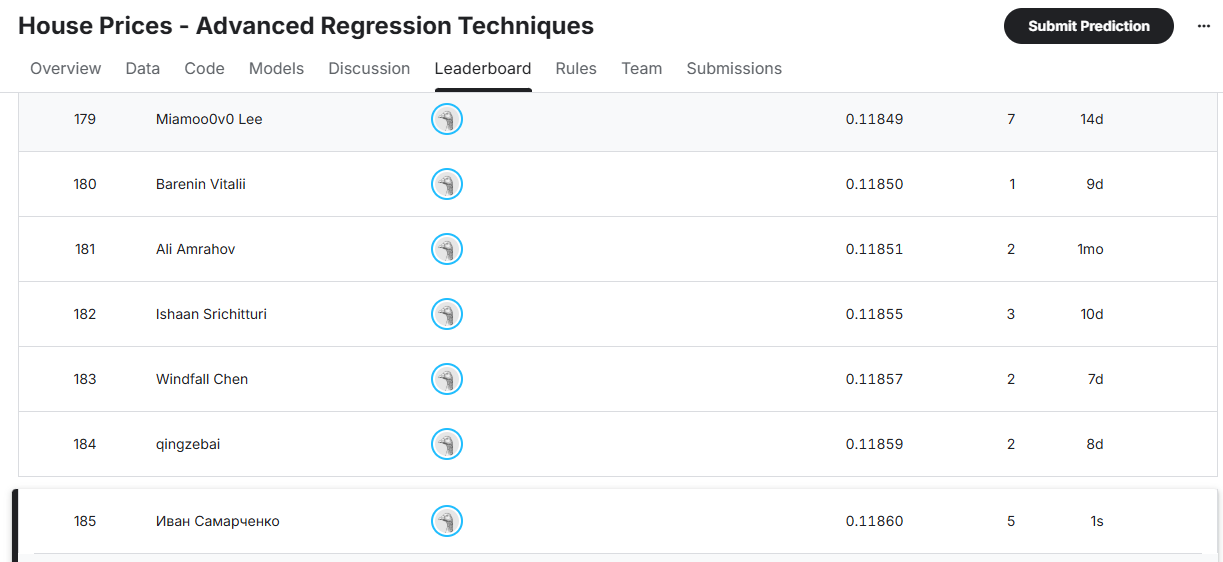